<a href="https://colab.research.google.com/github/sarcazm1/CMSC320FinalProjectSpotify/blob/main/Copy_of_CMSC320_Checkpoint2_Spotify.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

CMSC320 Project Checkpoint 2

Names: Ena Song, Olexiy (Alex) Slokvenko, Alan Deng, Andrew Li,  Noah Combatir, Aditya Agrawal

In [1]:
 %cd /content
![ -d CMSC320FinalProjectSpotify ] || git clone https://github.com/sarcazm1/CMSC320FinalProjectSpotify.git
%cd /content/CMSC320FinalProjectSpotify
!ls data

/content
/content/CMSC320FinalProjectSpotify
'spotify_data clean.csv'


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv("data/spotify_data clean.csv")

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (8582, 15)


,track_id,track_name,track_number,track_popularity,explicit,artist_name,artist_popularity,artist_followers,artist_genres,album_id,album_name,album_release_date,album_total_tracks,album_type,track_duration_min
0,3EJS5LyekDim1Tf5rBFmZl,Trippy Mane (ft. Project Pat),4,0,True,Diplo,77,2812821,moombahton,5QRFnGnBeMGePBKF2xTz5z,"d00mscrvll, Vol. 1",2025-10-31,9,album,1.55
1,1oQW6G2ZiwMuHqlPpP27DB,OMG!,1,0,True,Yelawolf,64,2363438,"country hip hop, southern hip hop",4SUmmwnv0xTjRcLdjczGg2,OMG!,2025-10-31,1,single,3.07
2,7mdkjzoIYlf1rx9EtBpGmU,Hard 2 Find,1,4,True,Riff Raff,48,193302,NaN,3E3zEAL8gUYWaLYB9L7gbp,Hard 2 Find,2025-10-31,1,single,2.55
3,67rW0Zl7oB3qEpD5YWWE5w,Still Get Like That (ft. Project Pat & Starrah),8,30,True,Diplo,77,2813710,moombahton,5QRFnGnBeMGePBKF2xTz5z,"d00mscrvll, Vol. 1",2025-10-31,9,album,1.69
4,15xptTfRBrjsppW0INUZjf,ride me like a harley,2,0,True,Rumelis,48,8682,dark r&b,06FDIpSHYmZAZoyuYtc7kd,come closer / ride me like a harley,2025-10-30,2,single,2.39


In [3]:
df.info()

display(df.isna().sum())

print("Dup rows:", df.duplicated().sum())
print("Dup track IDs:", df["track_id"].duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8582 entries, 0 to 8581
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   track_id            8582 non-null   object 
 1   track_name          8582 non-null   object 
 2   track_number        8582 non-null   int64  
 3   track_popularity    8582 non-null   int64  
 4   explicit            8582 non-null   bool   
 5   artist_name         8579 non-null   object 
 6   artist_popularity   8582 non-null   int64  
 7   artist_followers    8582 non-null   int64  
 8   artist_genres       5221 non-null   object 
 9   album_id            8582 non-null   object 
 10  album_name          8582 non-null   object 
 11  album_release_date  8582 non-null   object 
 12  album_total_tracks  8582 non-null   int64  
 13  album_type          8582 non-null   object 
 14  track_duration_min  8582 non-null   float64
dtypes: bool(1), float64(1), int64(5), object(8)
memory usag

,0
track_id,0
track_name,0
track_number,0
track_popularity,0
explicit,0
artist_name,3
artist_popularity,0
artist_followers,0
artist_genres,3361
album_id,0


Dup rows: 0
Dup track IDs: 0


In [4]:
df["album_release_date"] = pd.to_datetime(df["album_release_date"], format = "mixed")

df["release_year"] = df["album_release_date"].dt.year

df.info()

print(df.groupby("explicit")["artist_popularity"].describe())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8582 entries, 0 to 8581
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   track_id            8582 non-null   object        
 1   track_name          8582 non-null   object        
 2   track_number        8582 non-null   int64         
 3   track_popularity    8582 non-null   int64         
 4   explicit            8582 non-null   bool          
 5   artist_name         8579 non-null   object        
 6   artist_popularity   8582 non-null   int64         
 7   artist_followers    8582 non-null   int64         
 8   artist_genres       5221 non-null   object        
 9   album_id            8582 non-null   object        
 10  album_name          8582 non-null   object        
 11  album_release_date  8582 non-null   datetime64[ns]
 12  album_total_tracks  8582 non-null   int64         
 13  album_type          8582 non-null   object      

In [5]:
# Lets do the following
## Hypothesis test on explicit vs artist_popularity
# Lets jus say my Null Hyp. is: mean(artist_popularity) for tracks where explicit = true and explicit = false are the same
# Alternative Hyp. : means differ
# 2 independent groups: Two-sampele T test.

# List of hypotheses tests from class (7.3)
# Correlation / Regression, Z-test, One-sample t-test, Two-sample t-test, Paired t-test, Mann–Whitney U

import scipy as sc


# create table for explicit artists
exp = df.loc[df["explicit"] == True,  "artist_popularity"].rename("explicit_artist_popularity")


# create table for non-explicit artists
non = df.loc[df["explicit"] == False, "artist_popularity"].rename("non_explicit_artist_popularity")
print("exp table")
print(exp.head())
print("\nnon table")
print(non.head())

# run t-test
t, p_t = sc.stats.ttest_ind(exp, non, equal_var=False)
print("\nt value from t-test: ", t, ", p value from t-test: ", p_t);
# t: abs(t) larger means more likely the difference is NOT noise.
# p_t < 0.05 → reject H0, mean artist_popularity differs by explicit status.
if p_t < 0.05: # reject H_0
    print("REJECT: The mean artist_popularity for explicit vs non explicit differ")
else: # p >= 0.05, fail to reject H0
    print("FAIL to reject H0: no significant difference in mean artist_popularity")

print("\nmean artist_popularity for explicit: ", exp.mean(), "\nmean artist popularity for non-explicit: ", non.mean())


exp table
0    77
1    64
2    48
3    77
4    48
Name: explicit_artist_popularity, dtype: int64

non table
5     46
6     30
7     49
8      6
10    25
Name: non_explicit_artist_popularity, dtype: int64

t value from t-test:  17.31140896496976 , p value from t-test:  8.186324341420042e-65
REJECT: The mean artist_popularity for explicit vs non explicit differ

mean artist_popularity for explicit:  75.68994413407822 
mean artist popularity for non-explicit:  67.74028598072739


Difference in means = 7.95, 95% CI [7.05, 8.85]


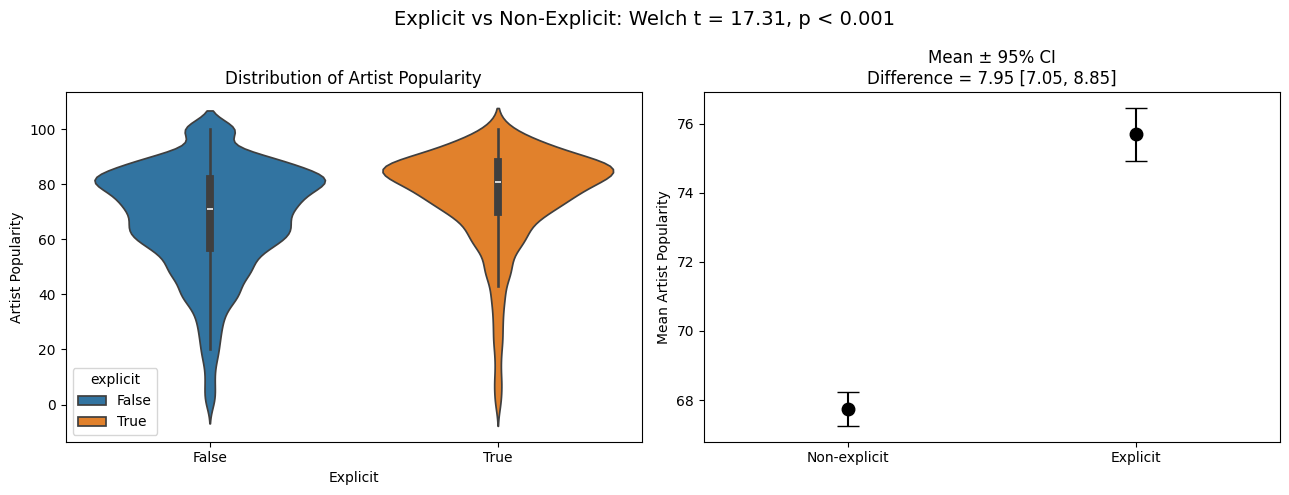

In [6]:
# Plot:
# 95% CI for each mean and for the difference (normal approx is fine at this n)
se_e = exp.std(ddof=1) / np.sqrt(len(exp))
se_n = non.std(ddof=1) / np.sqrt(len(non))
diff = exp.mean() - non.mean()
se_diff = np.sqrt(se_e**2 + se_n**2)
ci_lo, ci_hi = diff - 1.96*se_diff, diff + 1.96*se_diff
print(f"Difference in means = {diff:.2f}, 95% CI [{ci_lo:.2f}, {ci_hi:.2f}]")
# in 95% of expierments, the difference in means would fall between [7.05, 8.85]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: artist popularity distribution
sns.violinplot(data=df, x="explicit", y="artist_popularity", order=[False, True],
               hue="explicit", hue_order=[False, True],
               inner="box", legend=True, ax=axes[0])
axes[0].set_title("Distribution of Artist Popularity")
axes[0].set_xlabel("Explicit")
axes[0].set_ylabel("Artist Popularity")


# Right: mean, 95% CI
axes[1].errorbar([0, 1], [non.mean(), exp.mean()],
                 yerr=[1.96*se_n, 1.96*se_e],
                 fmt="o", color="black", ecolor="black", capsize=8, markersize=9)
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["Non-explicit", "Explicit"])
axes[1].set_xlim(-0.5, 1.5)
axes[1].set_ylabel("Mean Artist Popularity")
axes[1].set_title(f"Mean ± 95% CI\nDifference = {diff:.2f} [{ci_lo:.2f}, {ci_hi:.2f}]") # the mean, and the 95%CI bounds

plt.suptitle(f"Explicit vs Non-Explicit: Welch t = {t:.2f}, p < 0.001", fontsize=14)
plt.tight_layout()
plt.show()

```
For non-explicit: median approx 70 (white line), mean approx 67.74.
The distribution is left-skewed:
Most tracks come from fairly popular artists (the violin is widest around 80-85).
Some low-popularity artists that pulls the mean below the median.

For explicit: median approx 80 (white line), mean approx 75.69.
Also left-skewed (lower popularity artists make mean < median)
The violin is widest around 85-90 and the low-popularity tail (orange) is much thinner.
```

```
Overall Findings

Explicit tracks come from artists with higher mean popularity (75.7 vs. 67.7; 95% CI of the difference [7.05, 8.85]; p < 0.001 (low, so this is unlikely to be by chance)), so we reject null hypothesis.

The violin plot shows the explicit distribution shifted upward (median 81 vs. 71) but overlapping heavily. This is an correlation, not causation


```